In [1]:
!pip install shap lime sklearn-pandas anchor-exp -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 427.3/427.3 kB 14.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score
import xgboost as xgb
import shap
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
import warnings
warnings.filterwarnings('ignore')
import time

# Plot settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Seed for reproducibility
np.random.seed(42)

# Importing Models

In [3]:
import joblib
import os

# Local folder with the data and models
DATA_DIR = "data"
model_dir = DATA_DIR
model_list = []

# List all files in the directory
for filename in os.listdir(model_dir):
    if filename.endswith(".joblib"):
        file_path = os.path.join(model_dir, filename)
        try:
            # Load the model from the file
            model = joblib.load(file_path)
            model_list.append(model)
            print(f"Loaded model from: {filename}")
        except Exception as e:
            print(f"Error loading model from {filename}: {e}")

print(f"\nTotal models loaded: {len(model_list)}")

Loaded model from: random_forest_classifier_model.joblib
Loaded model from: hist_gradient_boosting_regressor_model.joblib
Loaded model from: logistic_regression_model.joblib

Total models loaded: 3


# Importing and Preparing the Dataset

In [ ]:
# Load the dataset
try:
    df = pd.read_csv(os.path.join(DATA_DIR, 'data_set_final.csv'))
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: Dataset file not found. Put 'data_set_final.csv' in the data/ folder.")
    df = None # Set df to None if file not found to prevent errors in subsequent cells

# Check if df was loaded before proceeding
if df is not None:
    # Apply the same preprocessing steps as in the training notebook

    # Drop columns
    columns_to_drop = ["CO_ESCOLA","NO_REGIAO_CODED"]
    df = df.drop(columns=columns_to_drop)
    print(f"\nDropped columns: {columns_to_drop}")

    # Convert categorical columns to 'category' type
    categorical_cols = [
        'SG_UF_CODED',
        'TP_DEPENDENCIA',
        'TP_CATEGORIA_ESCOCOLA_PRIVADA',
        'TP_LOCALIZACAO',
        'VINCULO',
        'LOCAL_FUNC'
    ]
    for col in categorical_cols:
        if col in df.columns:
            df[col] = df[col].astype('category')
        else:
            print(f"Warning: Categorical column '{col}' not found in the dataset.")

    # Identify columns to scale (assuming they are the same as in the training notebook)
    cols_to_scale = [col for col in df.columns if 'QT_' in col or '_POR_' in col]

    # Split data *before* scaling numerical features
    # Assuming 'PRESENCA_COMPLETA' is the target column
    if 'PRESENCA_COMPLETA' in df.columns:
        X = df.drop('PRESENCA_COMPLETA', axis=1)
        y = df['PRESENCA_COMPLETA']

        # Split into train and test
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

        # Scale features - Fit only on training data, transform both train and test
        scaler = StandardScaler()
        # Scale only the identified columns within X_train and X_test
        X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
        X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

        # Store feature names *after* dropping columns
        feature_names = X.columns.tolist()

        print(f"Train: {X_train.shape}")
        print(f"Test: {X_test.shape}")
        print(f"\nFeature names defined: {feature_names}")

    else:
        print("Error: 'PRESENCA_COMPLETA' column not found in the dataset. Please check the column name.")
        feature_names = [] # Initialize feature_names as empty list if target column not found
else:
    feature_names = [] # Initialize feature_names as empty list if dataset not loaded

Dataset loaded successfully.

Dropped columns: ['CO_ESCOLA', 'NO_REGIAO_CODED']
Treino: (20142, 69)
Teste: (5036, 69)

Feature names defined: ['TP_DEPENDENCIA', 'TP_CATEGORIA_ESCOLA_PRIVADA', 'TP_LOCALIZACAO', 'IN_PREDIO_COMPARTILHADO', 'IN_AREA_VERDE', 'IN_AUDITORIO', 'IN_BANHEIRO', 'IN_BIBLIOTECA', 'IN_DORMITORIO_ALUNO', 'IN_DORMITORIO_PROFESSOR', 'IN_LABORATORIO_CIENCIAS', 'IN_LABORATORIO_INFORMATICA', 'IN_PISCINA', 'IN_QUADRA_ESPORTES', 'IN_REFEITORIO', 'IN_SALA_LEITURA', 'IN_SALA_PROFESSOR', 'IN_SALA_REPOUSO_ALUNO', 'QT_SALAS_UTILIZADAS', 'QT_SALAS_UTILIZA_CLIMATIZADAS', 'IN_COMPUTADOR', 'IN_EQUIP_LOUSA_DIGITAL', 'IN_TABLET_ALUNO', 'IN_INTERNET', 'IN_INTERNET_ALUNOS', 'IN_PROF_BIBLIOTECARIO', 'IN_PROF_SAUDE', 'IN_PROF_COORDENADOR', 'IN_PROF_FONAUDIOLOGO', 'IN_PROF_NUTRICIONISTA', 'IN_PROF_PSICOLOGO', 'IN_PROF_ALIMENTACAO', 'IN_PROF_PEDAGOGIA', 'IN_PROF_SECRETARIO', 'IN_PROF_SEGURANCA', 'IN_PROF_MONITORES', 'IN_PROF_GESTAO', 'IN_PROF_ASSIST_SOCIAL', 'IN_EXAME_SELECAO', 'IN_REDES_SO

# LogisticRegression

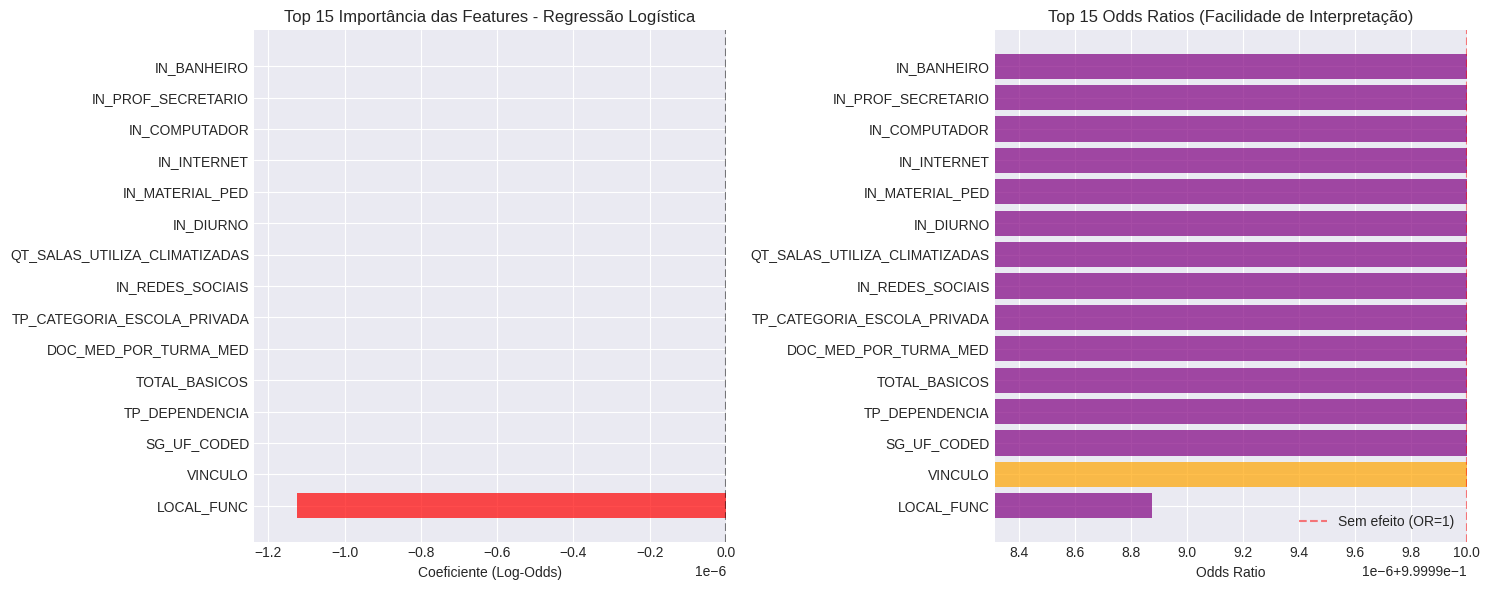

🔍 Interpretação dos Coeficientes:

Top 15 features mais importantes:
  📈 LOCAL_FUNC: diminui a chance de aprovação (coef: -0.000)
  📈 VINCULO: aumenta a chance de aprovação (coef: 0.000)
  📈 SG_UF_CODED: diminui a chance de aprovação (coef: -0.000)
  📈 TP_DEPENDENCIA: diminui a chance de aprovação (coef: -0.000)
  📈 TOTAL_BASICOS: diminui a chance de aprovação (coef: -0.000)
  📈 DOC_MED_POR_TURMA_MED: diminui a chance de aprovação (coef: -0.000)
  📈 TP_CATEGORIA_ESCOLA_PRIVADA: diminui a chance de aprovação (coef: -0.000)
  📈 IN_REDES_SOCIAIS: diminui a chance de aprovação (coef: -0.000)
  📈 QT_SALAS_UTILIZA_CLIMATIZADAS: diminui a chance de aprovação (coef: -0.000)
  📈 IN_DIURNO: diminui a chance de aprovação (coef: -0.000)
  📈 IN_MATERIAL_PED: diminui a chance de aprovação (coef: -0.000)
  📈 IN_INTERNET: diminui a chance de aprovação (coef: -0.000)
  📈 IN_COMPUTADOR: diminui a chance de aprovação (coef: -0.000)
  📈 IN_PROF_SECRETARIO: diminui a chance de aprovação (coef: -0.000)
  📈 

In [5]:
# Assuming feature_names is a list of feature names used to train the model
logistic_model = None
for model in model_list:
    if isinstance(model, LogisticRegression):
        logistic_model = model
        break

if logistic_model is not None:
    if len(feature_names) > 0 and logistic_model.coef_ is not None:
        if len(logistic_model.coef_[0]) == len(feature_names):
            # Interpret the Logistic Regression through its coefficients
            coef_df = pd.DataFrame({
                'Feature': feature_names, # Make sure feature_names is defined
                'Coefficient': logistic_model.coef_[0],
                'Abs_Coef': np.abs(logistic_model.coef_[0]),
                'Odds_Ratio': np.exp(logistic_model.coef_[0])
            }).sort_values('Abs_Coef', ascending=False)

            # Select top N features for visualization
            top_n = 15
            coef_df_top = coef_df.head(top_n)

            # Plot the coefficients
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

            # Chart 1: Coefficients
            colors = ['red' if x < 0 else 'green' for x in coef_df_top['Coefficient']]
            ax1.barh(coef_df_top['Feature'], coef_df_top['Coefficient'], color=colors, alpha=0.7)
            ax1.set_xlabel('Coefficient (Log-Odds)')
            ax1.set_title(f'Top {top_n} Feature Importance - Logistic Regression')
            ax1.axvline(x=0, color='black', linestyle='--', alpha=0.5)
            # Adjust x-axis limits for better visualization of small coefficients
            coef_min, coef_max = coef_df_top['Coefficient'].min(), coef_df_top['Coefficient'].max()
            ax1.set_xlim(coef_min - abs(coef_min)*0.1, coef_max + abs(coef_max)*0.1)


            # Chart 2: Odds Ratios
            colors_or = ['orange' if x > 1 else 'purple' for x in coef_df_top['Odds_Ratio']]
            ax2.barh(coef_df_top['Feature'], coef_df_top['Odds_Ratio'], color=colors_or, alpha=0.7)
            ax2.set_xlabel('Odds Ratio')
            ax2.set_title(f'Top {top_n} Odds Ratios (Easier to Interpret)')
            ax2.axvline(x=1, color='red', linestyle='--', alpha=0.5, label='No effect (OR=1)')
            ax2.legend()
            # Adjust x-axis limits for better visualization of small odds ratios
            or_min, or_max = coef_df_top['Odds_Ratio'].min(), coef_df_top['Odds_Ratio'].max()
            ax2.set_xlim(or_min - abs(or_min-1)*0.5, or_max + abs(or_max-1)*0.5)


            plt.tight_layout()
            plt.show()

            print("🔍 Interpreting the Coefficients:")
            print(f"\nTop {top_n} most important features:")
            for _, row in coef_df_top.iterrows():
                direction = "increases" if row['Coefficient'] > 0 else "decreases"
                print(f"  📈 {row['Feature']}: {direction} the chance of approval (coef: {row['Coefficient']:.3f})")
        else:
            print(f"Error: The number of features ({len(feature_names)}) does not match the number of coefficients in the logistic regression model ({len(logistic_model.coef_[0])}). Please ensure the dataset used to define feature_names is the same as the one used to train the model.")
    else:
        print("Error: feature_names is not defined or logistic_model.coef_ is not available.")
else:
    print("Logistic Regression model not found in model_list.")

# HistGradientBoostingRegressor

Checking model types in model_list:
  Found model of type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
  Found model of type: <class 'sklearn.ensemble._hist_gradient_boosting.gradient_boosting.HistGradientBoostingRegressor'>
Found HistGradientBoostingRegressor model: HistGradientBoostingRegressor

Using a sample of 500 instances from X_test for SHAP calculation.
Using TreeExplainer for regression model.
SHAP values calculated.


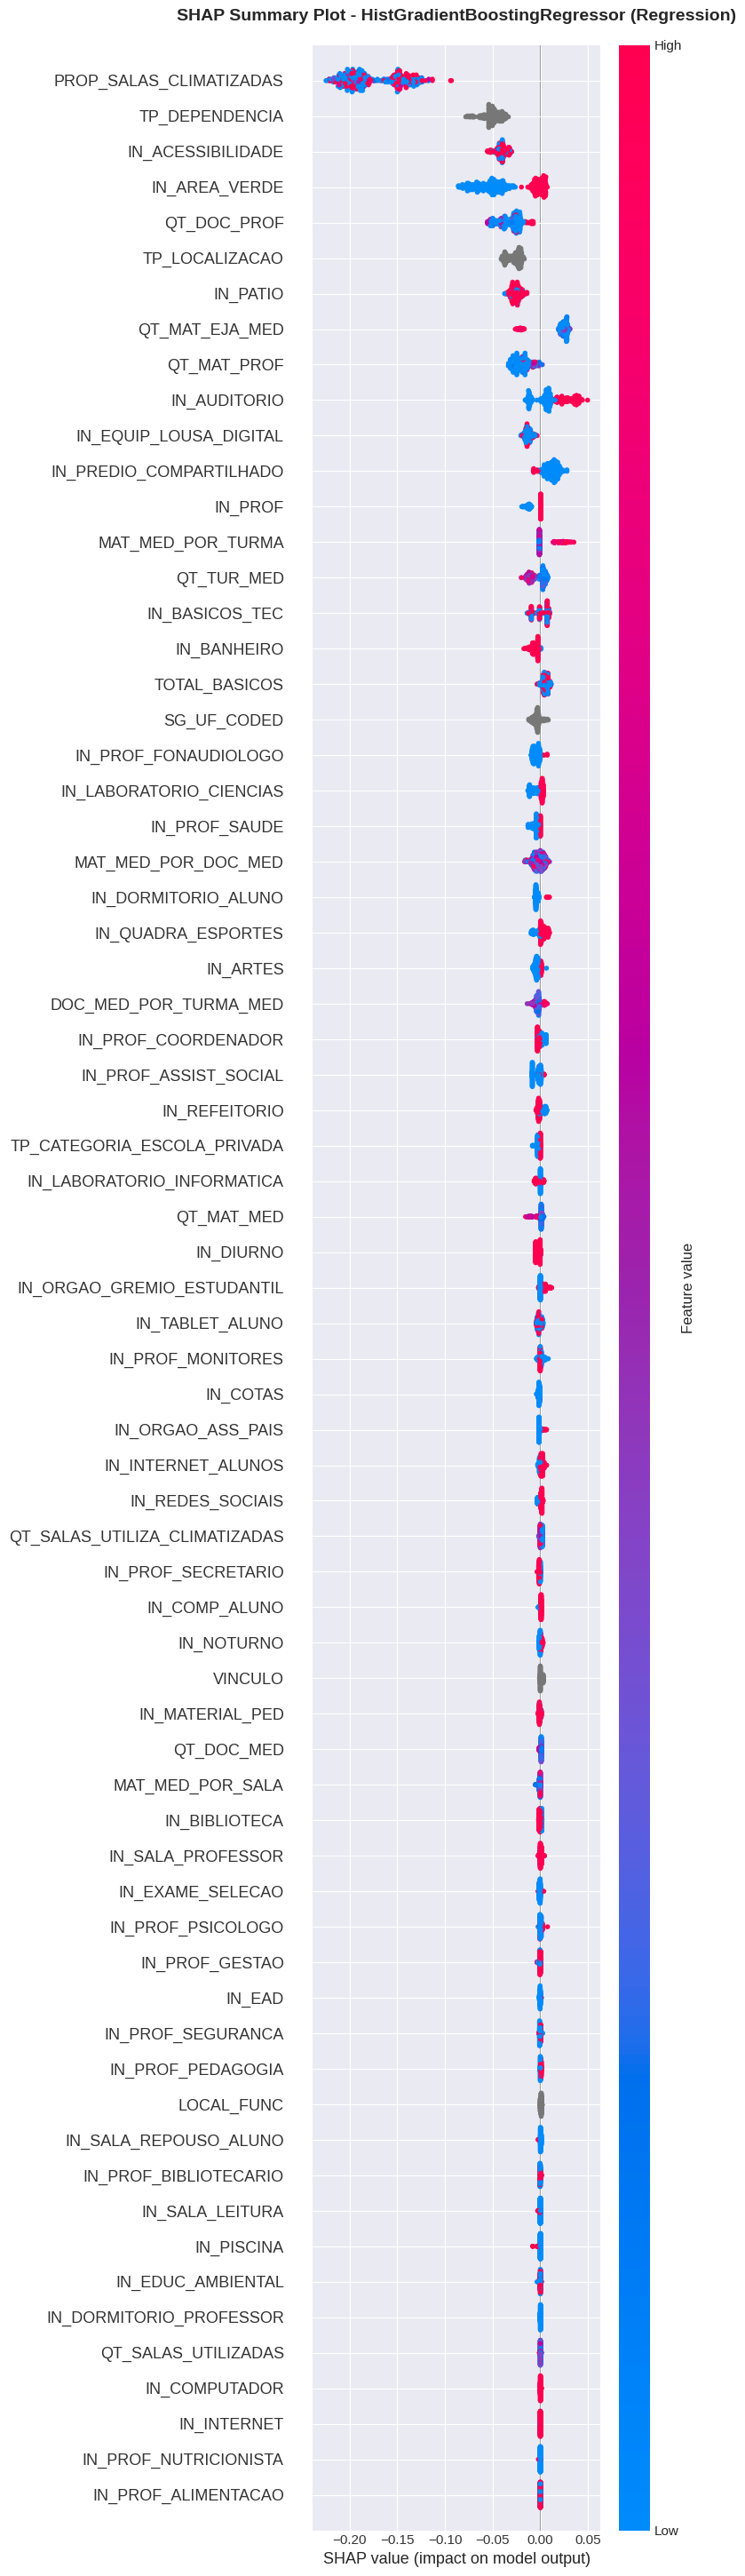

📘 Como interpretar o Summary Plot SHAP:
✔ Eixo Y: Features ordenadas por importância
✔ Eixo X: Valor SHAP (impacto na predição)
✔ Cor: Valor da feature (🔴 alto | 🔵 baixo)
✔ Dispersão: Variação do impacto


In [6]:
# Find the HistGradientBoostingRegressor model
hgb_model = None
print("Checking model types in model_list:")
for model in model_list:
    print(f"  Found model of type: {type(model)}")
    if isinstance(model, sklearn.ensemble._hist_gradient_boosting.gradient_boosting.HistGradientBoostingRegressor): # Corrected class type
        hgb_model = model
        print(f"Found HistGradientBoostingRegressor model: {type(hgb_model).__name__}")
        break

if hgb_model is not None and len(feature_names) > 0:
    # Sample X_test to make SHAP calculation faster
    if X_test.shape[0] > 500: # Adjust sample size as needed
        X_test_sample = shap.sample(X_test, 500, random_state=42)
        print(f"\nUsing a sample of {X_test_sample.shape[0]} instances from X_test for SHAP calculation.")
    else:
        X_test_sample = X_test
        print("\nUsing the entire X_test dataset for SHAP calculation.")

    # Initialize SHAP explainer for regression model
    explainer = shap.TreeExplainer(hgb_model)
    print("Using TreeExplainer for regression model.")

    # Calculate SHAP values
    shap_values = explainer.shap_values(X_test_sample)
    print("SHAP values calculated.")

    # Summary Plot: overview of feature importance
    plt.figure(figsize=(12, 8))

    # Create the summary plot for regression
    shap.summary_plot(
        shap_values, # Use shap_values directly for regression
        X_test_sample,
        feature_names=feature_names,
        max_display=150,
        show=False
    )

    plt.title('SHAP Summary Plot - HistGradientBoostingRegressor (Regression)', pad=20, fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

    print("📘 How to read the SHAP Summary Plot:")
    print("✔ Y axis: Features sorted by importance")
    print("✔ X axis: SHAP value (impact on the prediction)")
    print("✔ Color: Feature value (🔴 high | 🔵 low)")
    print("✔ Spread: Variation of the impact")

else:
    if hgb_model is None:
        print("HistGradientBoostingRegressor model not found in model_list for SHAP interpretation.")
    elif len(feature_names) == 0:
         print("Error: feature_names is not defined. Please ensure the dataset was loaded and processed correctly.")

In [7]:
# shap_values will be an array of shape (n_samples, n_features)
# Compute the mean absolute importance of each feature
feature_importance = np.mean(np.abs(shap_values), axis=0)

# Sort from most to least important
sorted_idx = np.argsort(feature_importance)[::-1]

# Build the list of sorted names
ordered_features = [feature_names[i] for i in sorted_idx]

print("\n📌 Order of the features in the SHAP plot (from most to least important):\n")
for rank, feat in enumerate(ordered_features[:150], start=1):
    print(f"{feat}")



📌 Ordem das features no gráfico SHAP (da mais importante para a menos importante):

PROP_SALAS_CLIMATIZADAS
TP_DEPENDENCIA
IN_ACESSIBILIDADE
IN_AREA_VERDE
QT_DOC_PROF
TP_LOCALIZACAO
IN_PATIO
QT_MAT_EJA_MED
QT_MAT_PROF
IN_AUDITORIO
IN_EQUIP_LOUSA_DIGITAL
IN_PREDIO_COMPARTILHADO
IN_PROF
MAT_MED_POR_TURMA
QT_TUR_MED
IN_BASICOS_TEC
IN_BANHEIRO
TOTAL_BASICOS
SG_UF_CODED
IN_PROF_FONAUDIOLOGO
IN_LABORATORIO_CIENCIAS
IN_PROF_SAUDE
MAT_MED_POR_DOC_MED
IN_DORMITORIO_ALUNO
IN_QUADRA_ESPORTES
IN_ARTES
DOC_MED_POR_TURMA_MED
IN_PROF_COORDENADOR
IN_PROF_ASSIST_SOCIAL
IN_REFEITORIO
TP_CATEGORIA_ESCOLA_PRIVADA
IN_LABORATORIO_INFORMATICA
QT_MAT_MED
IN_DIURNO
IN_ORGAO_GREMIO_ESTUDANTIL
IN_TABLET_ALUNO
IN_PROF_MONITORES
IN_COTAS
IN_ORGAO_ASS_PAIS
IN_INTERNET_ALUNOS
IN_REDES_SOCIAIS
QT_SALAS_UTILIZA_CLIMATIZADAS
IN_PROF_SECRETARIO
IN_COMP_ALUNO
IN_NOTURNO
VINCULO
IN_MATERIAL_PED
QT_DOC_MED
MAT_MED_POR_SALA
IN_BIBLIOTECA
IN_SALA_PROFESSOR
IN_EXAME_SELECAO
IN_PROF_PSICOLOGO
IN_PROF_GESTAO
IN_EAD
IN_PROF_SEG

# RandomForestClassifier

Checking model types in model_list:
  Found model of type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Found RandomForestClassifier model: RandomForestClassifier

Using a sample of 500 instances from X_test for SHAP calculation.
Using TreeExplainer for classification model.
SHAP values calculated.


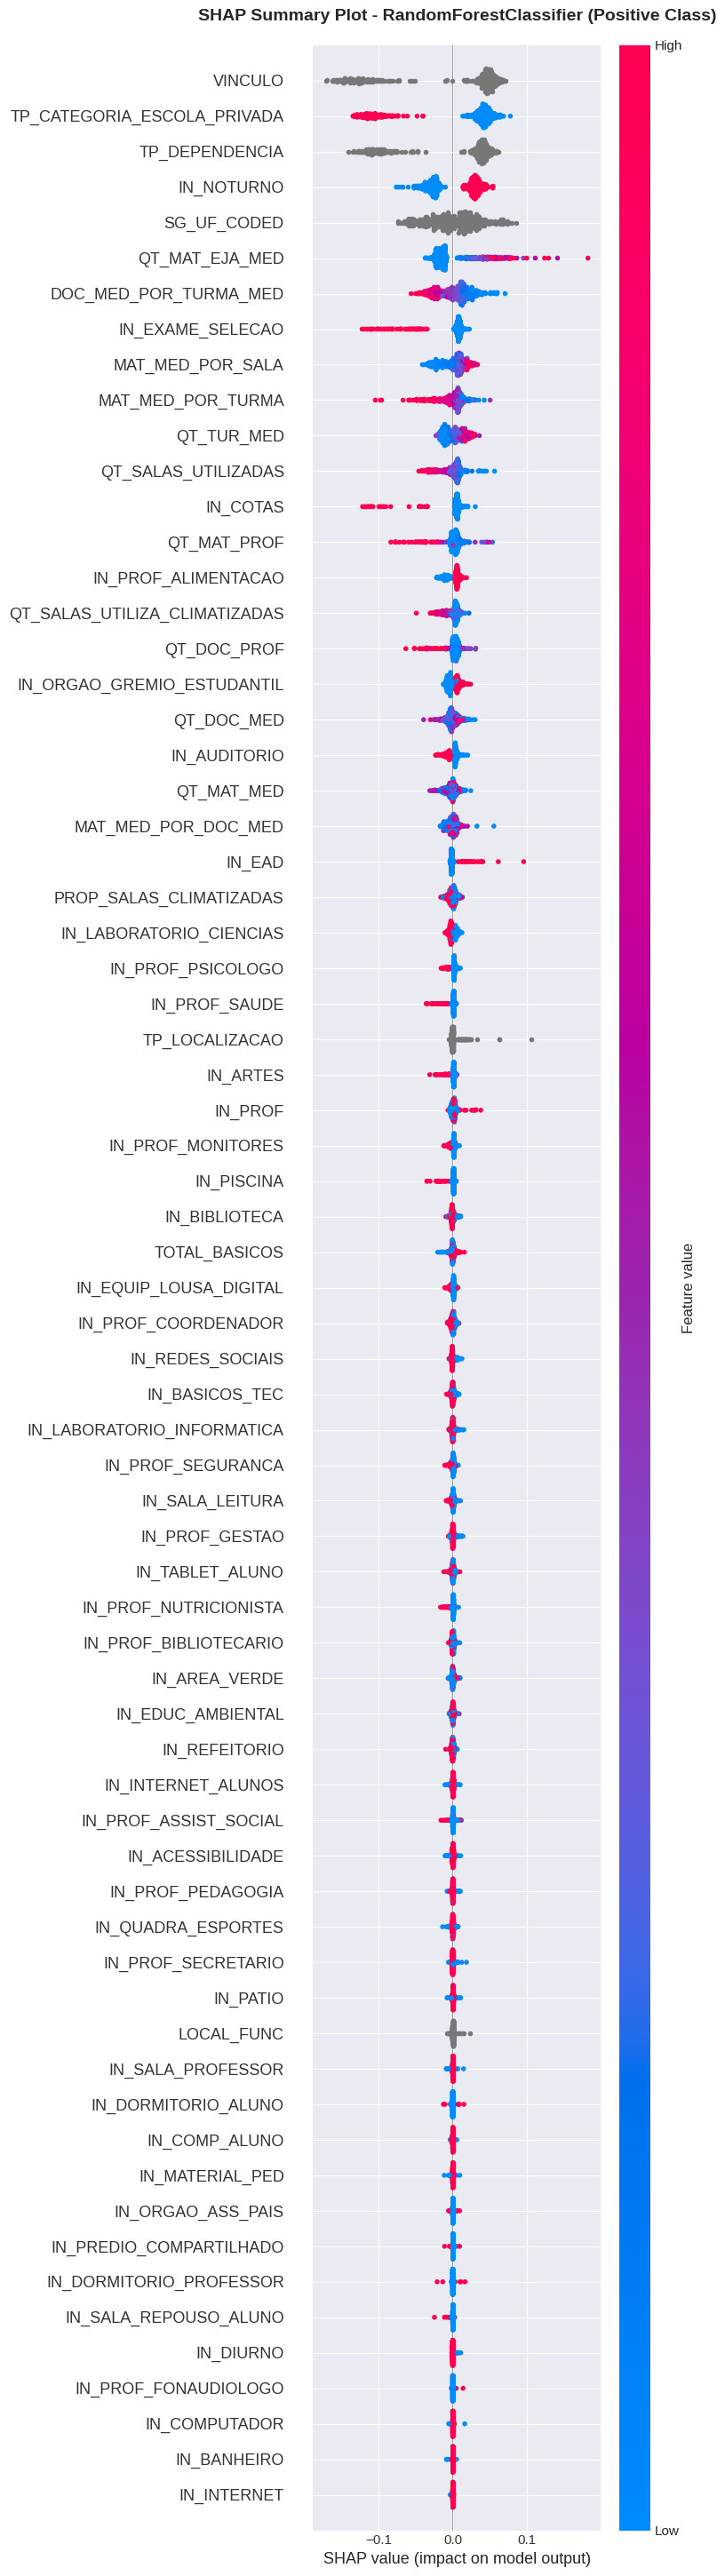

📘 Como interpretar o Summary Plot SHAP:
✔ Eixo Y: Features ordenadas por importância
✔ Eixo X: Valor SHAP (impacto na predição)
✔ Cor: Valor da feature (🔴 alto | 🔵 baixo)
✔ Dispersão: Variação do impacto


In [8]:
# Find the RandomForestClassifier model
rf_model = None
print("Checking model types in model_list:")
for model in model_list:
    print(f"  Found model of type: {type(model)}")
    if isinstance(model, RandomForestClassifier):
        rf_model = model
        print(f"Found RandomForestClassifier model: {type(rf_model).__name__}")
        break

if rf_model is not None and len(feature_names) > 0:
    # Sample X_test to make SHAP calculation faster
    if X_test.shape[0] > 500: # Adjust sample size as needed
        X_test_sample = shap.sample(X_test, 500, random_state=42)
        print(f"\nUsing a sample of {X_test_sample.shape[0]} instances from X_test for SHAP calculation.")
    else:
        X_test_sample = X_test
        print("\nUsing the entire X_test dataset for SHAP calculation.")

    # Initialize SHAP explainer for classification model
    explainer = shap.TreeExplainer(rf_model)
    print("Using TreeExplainer for classification model.")

    # Calculate SHAP values
    shap_values = explainer.shap_values(X_test_sample)
    print("SHAP values calculated.")

    # Summary Plot: overview of feature importance
    plt.figure(figsize=(12, 8))

    # Prepare SHAP values for binary classification plot (using the positive class)
    if hasattr(shap_values, 'values'):
        if len(shap_values.values.shape) == 3:
            shap_values_plot = shap_values.values[:, :, 1]
        else:
             # Handle cases where shap_values.values is not 3D but is an array
             shap_values_plot = shap_values.values
    else:
        # If shap_values is already an array
        if len(shap_values.shape) == 3:
            shap_values_plot = shap_values[:, :, 1]
        else:
            # Handle cases where shap_values is not 3D but is an array
            shap_values_plot = shap_values


    # Create the summary plot
    # The color represents the feature value: Red for high values, Blue for low values.
    shap.summary_plot(
        shap_values_plot,
        X_test_sample,
        feature_names=feature_names,
        max_display=150,
        show=False
    )

    plt.title('SHAP Summary Plot - RandomForestClassifier (Positive Class)', pad=20, fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

    print("📘 How to read the SHAP Summary Plot:")
    print("✔ Y axis: Features sorted by importance")
    print("✔ X axis: SHAP value (impact on the prediction)")
    print("✔ Color: Feature value (🔴 high | 🔵 low)") # Clarified color interpretation
    print("✔ Spread: Variation of the impact")

else:
    if rf_model is None:
        print("RandomForestClassifier model not found in model_list for SHAP interpretation.")
    elif len(feature_names) == 0:
         print("Error: feature_names is not defined. Please ensure the dataset was loaded and processed correctly.")